**1. Imports**

In [16]:
from eeg_framework.datasets      import *
from eeg_framework.preprocessing import *
from eeg_framework.plotting      import *
from eeg_framework.features      import *
from eeg_framework.models        import *
from eeg_framework.evaluate      import *

**2. Load Data**


In [17]:
root_dir = "data//BCI Competition 2020 - Track#3//"
subjects = [1]

epochs_train = load_bci2020_track3(root_dir=root_dir, split="train", subjects=subjects, concatenate=True)
epochs_test  = load_bci2020_track3(root_dir=root_dir, split="validation",  subjects=subjects, concatenate=True)

In [18]:
epochs_train

<EpochsArray | 300 events (all good), -0.5 – 2.602 s (baseline off), ~116.5 MiB, data loaded, with metadata,
 'hello': 60
 'help_me': 60
 'stop': 60
 'thank_you': 60
 'yes': 60>

**3. Preprocessing**

In [19]:
pipe_preprocessing = PreprocessingPipeline([
    ('filter', Filter(l_freq=None, h_freq=100.0, notch_freqs=60.0, notch_width=0.1)),
    ('ica',    ICA(random_state=0)),
    #('ar',     AutoReject(n_jobs=4)),
    ('car',    CAR()),
    # ...
])

epochs_train_f = pipe_preprocessing.fit_transform(epochs_train)
epochs_test_f  = pipe_preprocessing.transform(epochs_test)

[Pipeline] fit_transform → filter


/l/disk0/mcamboim/Documentos/Projetos/Brain2Speech/Paper CBEB/Framework/eeg_framework/preprocessing/preprocessing.py:400: RuntimeWarning: filter_length (1691) is longer than the signal (795), distortion is likely. Reduce filter length or filter a longer signal.
  data = mne.filter.notch_filter(


[Pipeline] fit_transform → ica


/l/disk0/mcamboim/Documentos/Projetos/Brain2Speech/Paper CBEB/Framework/eeg_framework/preprocessing/preprocessing.py:214: RuntimeWarning: The data has not been high-pass filtered. For good ICA performance, it should be high-pass filtered (e.g., with a 1.0 Hz lower bound) before fitting ICA.
  ica.fit(epochs_eeg, verbose=self.verbose)
/l/disk0/mcamboim/Documentos/Projetos/Brain2Speech/Paper CBEB/Framework/eeg_framework/preprocessing/preprocessing.py:310: RuntimeWarning: The provided Epochs instance does not seem to be referenced to a common average reference (CAR). ICLabel was designed to classify features extracted from an EEG dataset referenced to a CAR (see the 'set_eeg_reference()' method for Raw and Epochs instances).
  labels = label_components(epochs, ica, method='iclabel')
/l/disk0/mcamboim/Documentos/Projetos/Brain2Speech/Paper CBEB/Framework/eeg_framework/preprocessing/preprocessing.py:310: RuntimeWarning: The provided Epochs instance is not filtered between 1 and 100 Hz. ICLa

  [ICLabel] component 00: eye blink (1.00)
  [ICLabel] component 01: heart beat (0.77)
  [ICLabel] component 02: eye blink (0.92)
[ICA] strategy=icalabel | components removed: [0, 1, 2]
[Pipeline] fit_transform → car
[Pipeline] applying → filter


/l/disk0/mcamboim/Documentos/Projetos/Brain2Speech/Paper CBEB/Framework/eeg_framework/preprocessing/preprocessing.py:400: RuntimeWarning: filter_length (1691) is longer than the signal (795), distortion is likely. Reduce filter length or filter a longer signal.
  data = mne.filter.notch_filter(


[Pipeline] applying → ica
[Pipeline] applying → car


**4. Plotting**

Topomap - Topographic Map

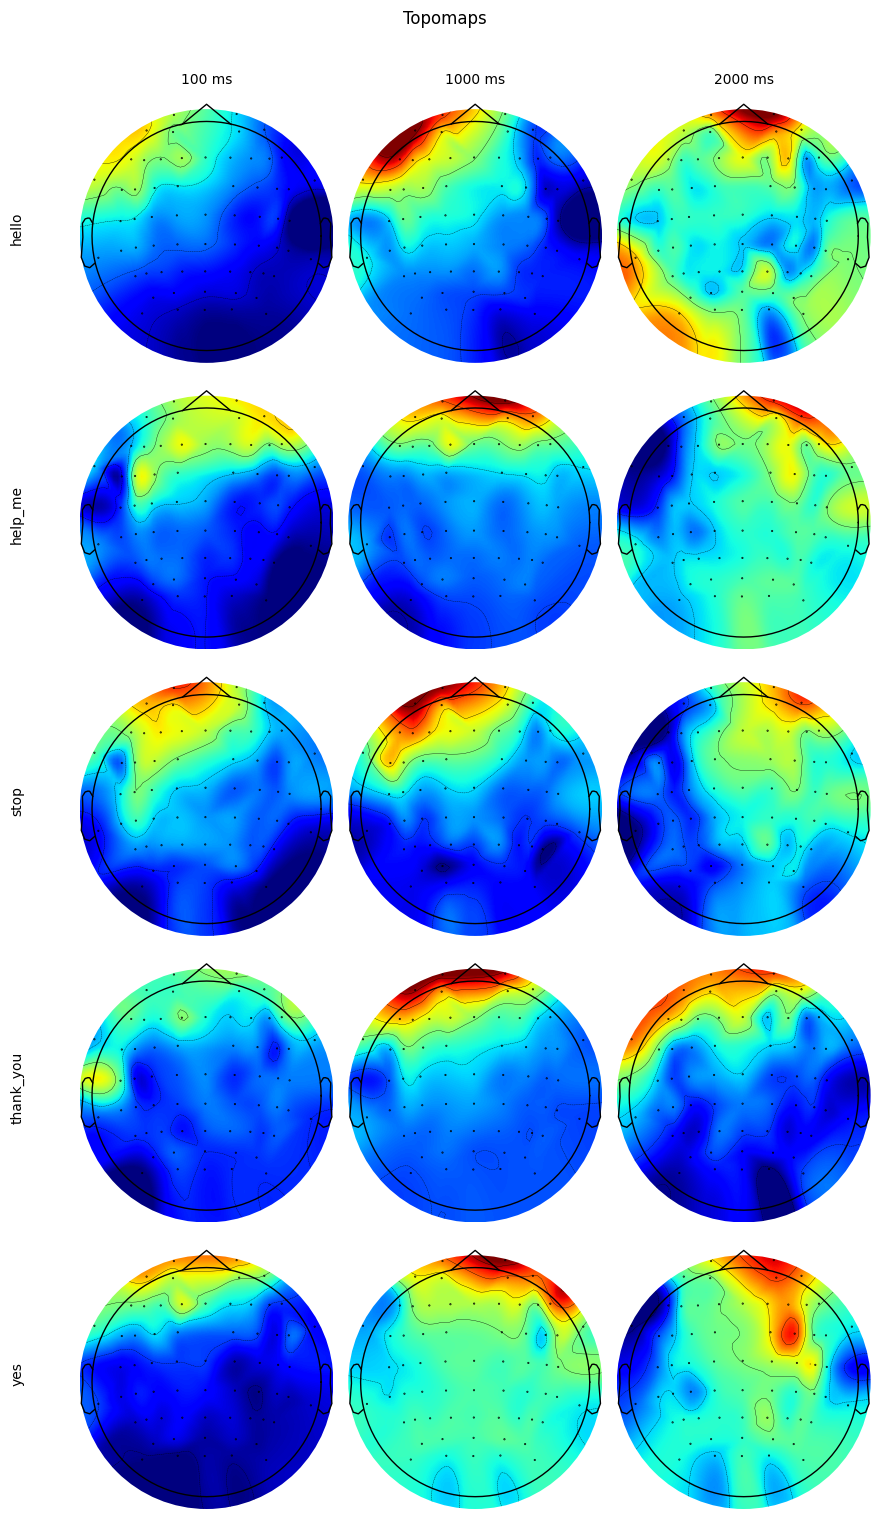

In [20]:
times = [0.1, 1.0, 2.0] # Time [s]
# Before processing
plot_topomap(epochs_train, times = times)
# After processing
#plot_topomap(epochs_train_f, times = times)

PSD - Power Spectral Density

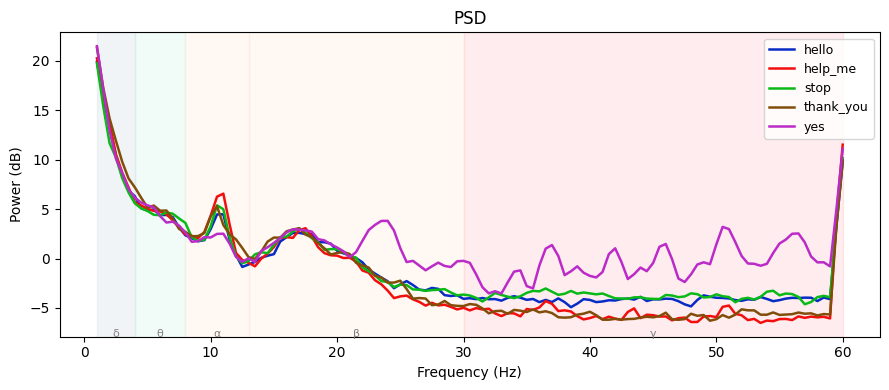

In [21]:
# Before preprocessing
plot_psd(epochs_train)
# After preprocessing
#plot_psd(epochs_train_f)

TFR - Time-frequency

In [22]:
# Before preprocessing
# plot_tfr(epochs_train)
# After preprocessing
#plot_tfr(epochs_train_f)

**5. Features**

In [23]:
pipe_feature = FeaturePipeline([
    ('CSP', CSP()),
    # ...
])

X_train, y_train = pipe_feature.fit_transform(epochs_train_f)
X_test, y_test = pipe_feature.transform(epochs_test_f)

[FeaturePipeline] fitting → CSP
Computing rank from data with rank=None
    Using tolerance 1.2e+03 (2.2e-16 eps * 64 dim * 8.3e+16  max singular value)
    Estimated rank (data): 62
    data: rank 62 computed from 64 data channels with 0 projectors
    Setting small data eigenvalues to zero (without PCA)
Reducing data rank from 64 -> 62
Estimating class=0 covariance using EMPIRICAL
Done.
Estimating class=1 covariance using EMPIRICAL
Done.
    Setting small data eigenvalues to zero (without PCA)
Computing rank from data with rank=None
    Using tolerance 1.2e+03 (2.2e-16 eps * 64 dim * 8.3e+16  max singular value)
    Estimated rank (data): 62
    data: rank 62 computed from 64 data channels with 0 projectors
    Setting small data eigenvalues to zero (without PCA)
Reducing data rank from 64 -> 62
Estimating class=0 covariance using EMPIRICAL
Done.
Estimating class=1 covariance using EMPIRICAL
Done.
    Setting small data eigenvalues to zero (without PCA)
Computing rank from data with 

**6. Classification**

In [24]:
from sklearn.svm import SVC

# EEGNet Example
clf_model = SVC(kernel='rbf', probability=True, random_state=42)

clf_model.fit(X_train, y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide `.",True
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


**7. Evaluation**

─────────────────────────────────────────────
  Accuracy        : 0.8600
  F1 (macro)      : 0.8634
  F1 (weighted)   : 0.8634
  Recall (macro)  : 0.8600
  Cohen's Kappa   : 0.8250
─────────────────────────────────────────────
  Class           Accuracy        F1    Recall
─────────────────────────────────────────────
  0                 0.9000    0.9474    0.9000
  1                 0.9000    0.8182    0.9000
  2                 0.8000    0.7619    0.8000
  3                 0.8000    0.8421    0.8000
  4                 0.9000    0.9474    0.9000
─────────────────────────────────────────────


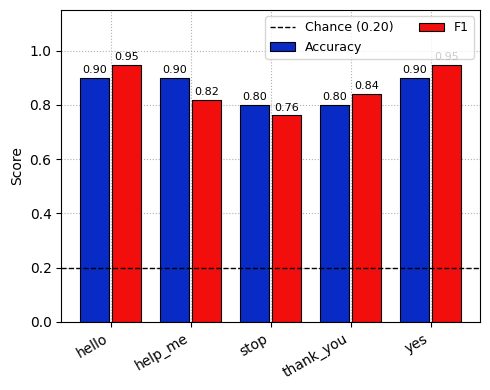

In [25]:
class_names = list(epochs_train.event_id.keys())
y_pred = clf_model.predict(X_test)

# Metrics
summary(y_test, y_pred)

# Plots
fig = plot_metrics_bar(y_test, y_pred, class_names=class_names, metrics=["accuracy","f1"])
# ....

**8. t-SNE**

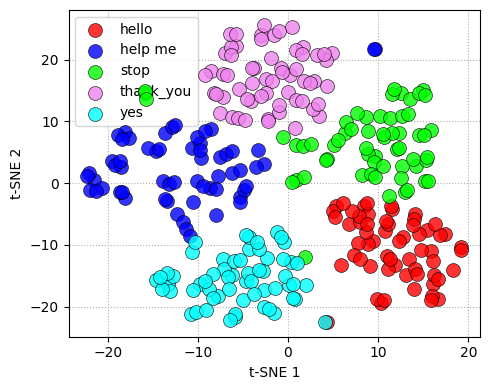

In [26]:
plot_tsne(X_train, y_train, class_names={0: "hello", 1: "help me", 2: "stop", 3: "thank_you", 4: "yes"})